<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Opinion%20Mining%20on%20product/service%20reviews%20dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


OPINION MINING RESULTS

                                     Review                        Cleaned Review  Polarity  Subjectivity Sentiment
This product is amazing and works perfectly       product amazing works perfectly  0.800000      0.950000  Positive
        Excellent quality and fast delivery       excellent quality fast delivery  0.600000      0.800000  Positive
             I absolutely love this product               absolutely love product  0.500000      0.600000  Positive
      The customer service was very helpful              customer service helpful  0.200000      0.300000  Positive
     Great experience and wonderful support    great experience wonderful support  0.900000      0.875000  Positive
           The product is worth every penny             product worth every penny  0.300000      0.100000  Positive
           Very satisfied with the purchase                    satisfied purchase  0.650000      1.000000  Positive
                 The quality is outstanding    

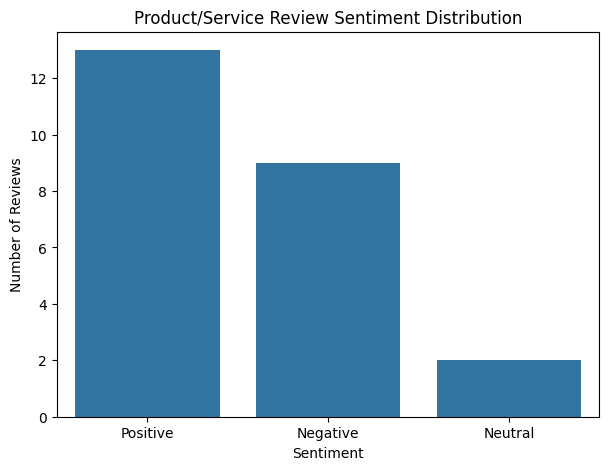

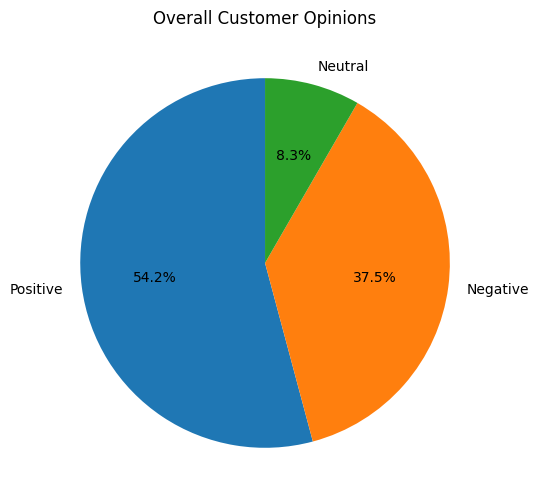

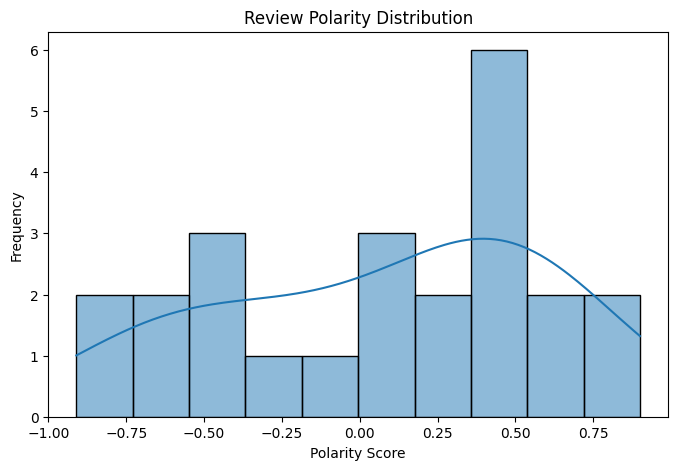

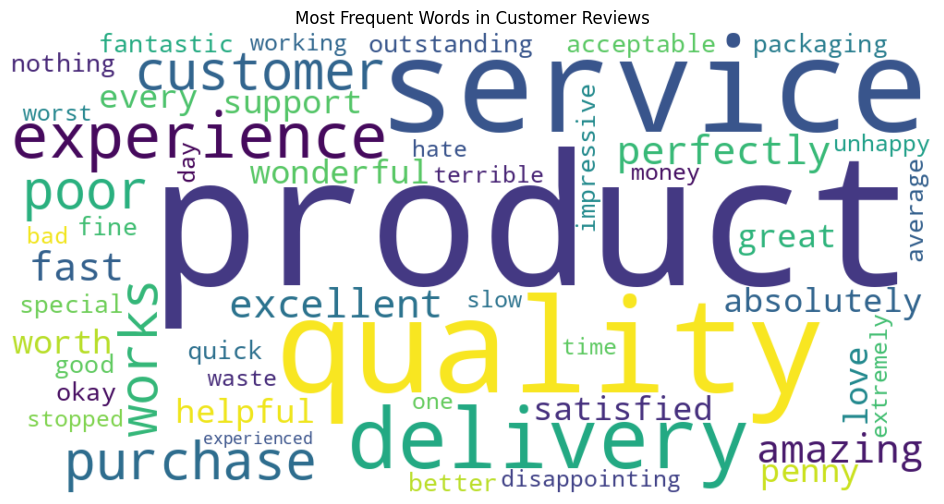


TOP 10 FREQUENT WORDS
      Word  Frequency
   product          9
   quality          4
   service          4
  delivery          3
experience          3
     works          2
  customer          2
  purchase          2
      poor          2
   amazing          1

OVERALL OPINION SUMMARY
Positive: 13 reviews (54.17%)
Negative: 9 reviews (37.50%)
Neutral: 2 reviews (8.33%)

Overall Average Polarity: 0.076
Overall Average Subjectivity: 0.617

CUSTOM REVIEW ANALYSIS
Review: The product quality is excellent and customer service is amazing
Polarity: 0.8
Sentiment: Positive

Opinion Mining Completed Successfully!


In [7]:

# Opinion Mining on Product/Service Reviews Dataset

!pip install -q pandas nltk textblob matplotlib seaborn wordcloud

import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from textblob import TextBlob
from nltk.corpus import stopwords
from wordcloud import WordCloud
from collections import Counter

nltk.download('stopwords', quiet=True)

# Sample product/service reviews dataset
data = {
    'Review': [
        "This product is amazing and works perfectly",
        "Excellent quality and fast delivery",
        "I absolutely love this product",
        "The customer service was very helpful",
        "Great experience and wonderful support",
        "The product is worth every penny",
        "Very satisfied with the purchase",
        "The quality is outstanding",
        "This is a fantastic product",
        "Delivery was quick and packaging was good",
        "The product is average and okay",
        "Nothing special about this product",
        "The service was acceptable",
        "It works fine but could be better",
        "The product is not very impressive",
        "Poor quality and disappointing experience",
        "I hate this product",
        "Very bad customer service",
        "The product stopped working after one day",
        "Waste of money and time",
        "Terrible experience and slow delivery",
        "The quality is extremely poor",
        "I am unhappy with this purchase",
        "Worst service ever experienced"
    ]
}

df = pd.DataFrame(data)

# Text preprocessing
stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df['Cleaned Review'] = df['Review'].apply(preprocess)

# Opinion mining using TextBlob
def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

df['Polarity'] = df['Review'].apply(
    lambda x: TextBlob(x).sentiment.polarity
)

df['Subjectivity'] = df['Review'].apply(
    lambda x: TextBlob(x).sentiment.subjectivity
)

df['Sentiment'] = df['Review'].apply(get_sentiment)

# Display review analysis
print("\nOPINION MINING RESULTS\n")
print(df.to_string(index=False))

# Sentiment distribution
sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)
plt.title("Product/Service Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# Sentiment pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Overall Customer Opinions")
plt.show()

# Polarity distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['Polarity'], bins=10, kde=True)
plt.title("Review Polarity Distribution")
plt.xlabel("Polarity Score")
plt.ylabel("Frequency")
plt.show()

# Generate word cloud
all_words = " ".join(df['Cleaned Review'])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='viridis'
).generate(all_words)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequent Words in Customer Reviews")
plt.show()

# Most frequent words
word_frequency = Counter(all_words.split())
top_words = word_frequency.most_common(10)

words_df = pd.DataFrame(
    top_words,
    columns=['Word', 'Frequency']
)

print("\nTOP 10 FREQUENT WORDS")
print(words_df.to_string(index=False))

# Overall opinion summary
print("\nOVERALL OPINION SUMMARY")

for sentiment, count in sentiment_counts.items():
    percentage = count / len(df) * 100
    print(f"{sentiment}: {count} reviews ({percentage:.2f}%)")

print("\nOverall Average Polarity:", round(df['Polarity'].mean(), 3))
print("Overall Average Subjectivity:", round(df['Subjectivity'].mean(), 3))

# Custom review prediction
custom_review = "The product quality is excellent and customer service is amazing"

custom_polarity = TextBlob(custom_review).sentiment.polarity

print("\nCUSTOM REVIEW ANALYSIS")
print("Review:", custom_review)
print("Polarity:", round(custom_polarity, 3))
print("Sentiment:", get_sentiment(custom_review))

print("\nOpinion Mining Completed Successfully!")
